# Week 3: Statistical Modeling and Hypothesis Testing
**Dataset:** Titanic passengers, `titanic_cleaned.csv` (Week 1 output; 891 rows, no missing values). Week 2 EDA is the starting point for the hypotheses.

**Plan**
1. State the research question and hypotheses *before* fitting anything.
2. Check the assumptions of logistic regression (events per variable, multicollinearity, linearity of the logit) and fix what fails.
3. Build nested models, compare them with likelihood-ratio tests and information criteria, and estimate parameters with confidence intervals.
4. Evaluate performance on held-out data (hold-out split and repeated cross-validation), including calibration.
5. Run residual and influence diagnostics, then sensitivity analyses.
6. Fit a supplementary **linear regression** with a full OLS diagnostic workflow (R-squared, residuals, heteroscedasticity, normality, multicollinearity).
7. Interpret every result against the original hypotheses and state limitations.

## 1. Setup and data

In [1]:
import json, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score, brier_score_loss, confusion_matrix)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED = "#1F5C99", "#C0504D"
os.makedirs("w3_charts", exist_ok=True)
R = {}                                   # results collected for the report
def save(name): plt.tight_layout(); plt.savefig(f"w3_charts/{name}.png", dpi=170); plt.show()

df = pd.read_csv("titanic_cleaned.csv")           # Week 1 output
df["Pclass"] = df.Pclass.astype(int)
df["Female"] = (df.Sex == "Female").astype(int)
df["P2"] = (df.Pclass == 2).astype(int); df["P3"] = (df.Pclass == 3).astype(int)
df["Emb_C"] = (df.Embarked == "Cherbourg").astype(int); df["Emb_Q"] = (df.Embarked == "Queenstown").astype(int)
FS_MEAN = df.Family_Size.mean()
df["FS_c"] = df.Family_Size - FS_MEAN; df["FS_c2"] = df.FS_c ** 2      # centred linear and quadratic family size
df["Age_lnAge"] = df.Age * np.log(df.Age)                              # for the Box-Tidwell linearity test
df["LA"] = np.log(df.Age)                                              # log(Age), the functional form chosen in Section 3
df["Age_c"] = df.Age - 30; df["Age_c2"] = df.Age_c ** 2; df["Child"] = (df.Age < 13).astype(int); df["Age_u15"] = np.minimum(df.Age, 15)
print(df.shape, "missing:", int(df.isna().sum().sum()))
df[["Survived","Female","Pclass","Age","Family_Size","Embarked"]].head()

(891, 39) missing: 0


,Survived,Female,Pclass,Age,Family_Size,Embarked
0,0,0,3,22.0,2,Southampton
1,1,1,1,38.0,2,Cherbourg
2,1,1,3,26.0,1,Southampton
3,1,1,1,35.0,2,Southampton
4,0,0,3,35.0,1,Southampton


## Research question and hypotheses
**Primary question:** Which passenger characteristics are independently associated with survival, and does the survival advantage of women depend on passenger class?

| ID | Hypothesis (alternative) | Null | Test |
|---|---|---|---|
| H1 | Women have higher odds of survival than men, in every class | OR = 1 | Wald test of sex OR within each class |
| H2 | Odds of survival fall with lower class | no class differences | Wald tests of class contrasts, by sex |
| H3 | The sex effect differs between classes (interaction) | same sex OR in all classes | Likelihood-ratio test, 2 df |
| H4 | Odds of survival decline with age | no age effect | Likelihood-ratio test |
| H5 | Family size has an inverted-U effect (alone and very large families do worse) | no family-size effect | Likelihood-ratio test of the linear + quadratic terms |
| H6 | Port of embarkation has no independent effect once sex, class, age and family are controlled (the Week 2 Cherbourg advantage was confounding) | no port effect | Likelihood-ratio test, 2 df |

**Secondary question (linear regression):** what explains the price paid per person?
- **S1:** class explains most of the variation in per-person price (Week 2 suggested Fare is a class proxy).
- **S2:** port has an effect on price after controlling for class.

Significance level 0.05; with six primary hypotheses the Bonferroni threshold is 0.0083. No conclusion below changes under that stricter threshold.

## 2. Preparing for modelling: assumption checks (logistic regression)

In [2]:
# (a) Events per variable, (b) multicollinearity (VIF), (c) linearity of the logit in Age (Box-Tidwell), (d) separation
events = int(df.Survived.sum()); nonevents = int(len(df) - events)
pred_cols = ["Female","P2","P3","LA","FS_c","FS_c2","Emb_C","Emb_Q"]
Xv = sm.add_constant(df[pred_cols])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=pred_cols).round(2)
bt = smf.logit("Survived ~ Female + P2 + P3 + Age + Age_lnAge + FS_c + FS_c2 + Emb_C + Emb_Q", data=df).fit(disp=0)
R["assump"] = {"events": events, "nonevents": nonevents, "epv": round(min(events, nonevents)/len(pred_cols), 1),
               "vif": vif.to_dict(), "boxtidwell_age_p": float(bt.pvalues["Age_lnAge"]),
               "boxtidwell_age_coef": float(bt.params["Age_lnAge"])}
print(R["assump"]); vif

{'events': 342, 'nonevents': 549, 'epv': 42.8, 'vif': {'Female': 1.13, 'P2': 1.64, 'P3': 1.88, 'LA': 1.35, 'FS_c': 3.83, 'FS_c2': 3.37, 'Emb_C': 1.14, 'Emb_Q': 1.1}, 'boxtidwell_age_p': 0.001067659262517548, 'boxtidwell_age_coef': 0.0587430728345791}


Female    1.13
P2        1.64
P3        1.88
LA        1.35
FS_c      3.83
FS_c2     3.37
Emb_C     1.14
Emb_Q     1.10
dtype: float64

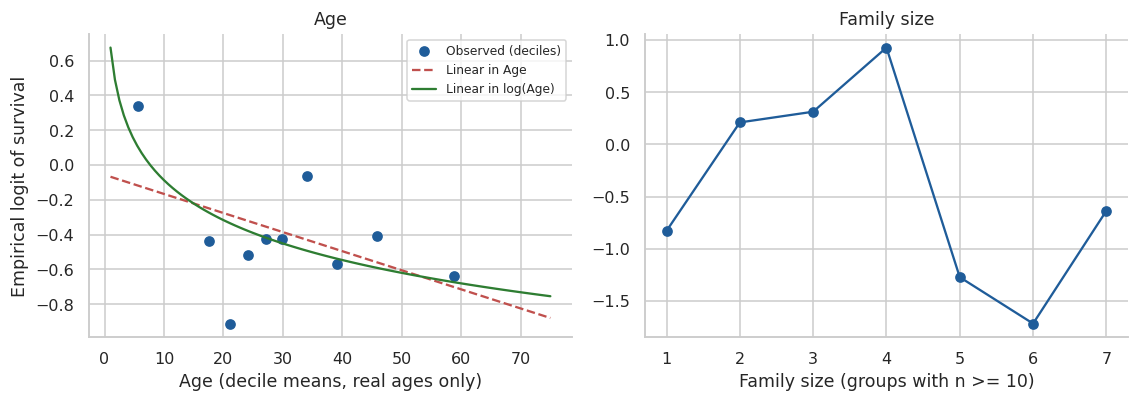

In [3]:
# Empirical logit of survival against Age and Family size (checks the functional form visually)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
real = df[df.Age_Imputed == 0].copy(); real["bin"] = pd.qcut(real.Age, 10, duplicates="drop")
g = real.groupby("bin", observed=True).agg(n=("Survived","size"), s=("Survived","sum"), x=("Age","mean"))
ax[0].plot(g.x, np.log((g.s+.5)/(g.n-g.s+.5)), "o", color=BLUE, label="Observed (deciles)")
xa = np.linspace(1, 75, 100)
ml = smf.logit("Survived ~ Age", data=real).fit(disp=0); mg = smf.logit("Survived ~ np.log(Age)", data=real.assign(Age=real.Age.clip(lower=0.4))).fit(disp=0)
ax[0].plot(xa, ml.params["Intercept"] + ml.params["Age"]*xa, "--", color=RED, label="Linear in Age"); ax[0].plot(xa, mg.params["Intercept"] + mg.params["np.log(Age)"]*np.log(xa), "-", color="#2E7D32", label="Linear in log(Age)"); ax[0].legend(fontsize=8)
ax[0].set_xlabel("Age (decile means, real ages only)"); ax[0].set_ylabel("Empirical logit of survival"); ax[0].set_title("Age")
g2 = df.groupby("Family_Size").agg(n=("Survived","size"), s=("Survived","sum"))
g2 = g2[g2.n >= 10]
ax[1].plot(g2.index, np.log((g2.s+.5)/(g2.n-g2.s+.5)), "o-", color=BLUE); ax[1].set_xlabel("Family size (groups with n >= 10)"); ax[1].set_title("Family size")
save("01_logit_linearity")

**Results of the assumption checks**
- **Events per variable:** 342 survivors and 549 deaths for 8 predictors, i.e. about 43 events per variable (guideline: at least 10). The sample is ample for this model.
- **Multicollinearity:** all variance inflation factors are below 4 (largest 3.8 for the centred family-size terms; guideline: below 5 to 10). Centring family size before squaring it kept the linear and quadratic terms from being almost perfectly correlated.
- **Linearity of the logit in Age: violated.** The Box-Tidwell test on a model with Age in a straight line is significant (p = 0.001), and the plot shows the empirical logit dropping steeply for young children and then flattening, which a straight line cannot follow. Family size is visibly non-linear as well (inverted U), which is why a quadratic term is included.
- **Independence:** passengers who travelled together are not independent. This cannot be fixed with the available data and is listed as a limitation; robust standard errors are used as a check in Section 7.

## 3. Remedy for the Age non-linearity: choosing a functional form

The Box-Tidwell test rejects a straight-line effect of Age on the log-odds. Candidate functional forms are compared on information criteria and on calibration (Hosmer-Lemeshow), all inside the same base model (sex, class, family size, port and the sex x class interaction).

In [4]:
def hl_test(y, p, g=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}); d["grp"] = pd.qcut(d.p.rank(method="first"), g, labels=False)
    t = d.groupby("grp").agg(n=("y","size"), obs=("y","sum"), exp=("p","sum"), pbar=("p","mean"))
    chi2 = (((t.obs - t.exp)**2) / (t.exp * (1 - t.pbar))).sum(); return float(chi2), g-2, float(stats.chi2.sf(chi2, g-2)), t
BASE = "Survived ~ Female + P2 + P3 + FS_c + FS_c2 + Emb_C + Emb_Q + Female:P2 + Female:P3"
forms = {"Linear in Age": " + Age", "Quadratic in Age": " + Age_c + Age_c2", "Child indicator (<13) + linear": " + Age + Child",
         "Piecewise linear (knot at 15)": " + Age + Age_u15", "Natural cubic spline (3 df)": " + cr(Age, df=3)", "log(Age)": " + LA"}
rows = []
for k, v in forms.items():
    mm = smf.logit(BASE + v, data=df).fit(disp=0); c_, d_, p_, _ = hl_test(df.Survived, mm.predict(df))
    rows.append({"form": k, "k": int(mm.df_model)+1, "logLik": round(mm.llf,1), "AIC": round(mm.aic,1), "BIC": round(mm.bic,1), "HL_p": round(p_,3)})
R["age_forms"] = rows
# does the chosen form still leave curvature? (LR test for adding a squared log(Age) term)
m_la = smf.logit(BASE + " + LA", data=df).fit(disp=0); m_la2 = smf.logit(BASE + " + LA + I(LA**2)", data=df).fit(disp=0)
st_ = 2*(m_la2.llf - m_la.llf); R["age_resid_curv_p"] = float(stats.chi2.sf(st_, 1))
print(pd.DataFrame(rows).to_string(index=False)); print("curvature left in log(Age):", R["age_resid_curv_p"])

                          form  k  logLik   AIC   BIC  HL_p
                 Linear in Age 11  -369.6 761.1 813.9 0.014
              Quadratic in Age 12  -365.1 754.2 811.7 0.130
Child indicator (<13) + linear 12  -362.2 748.4 805.9 0.158
 Piecewise linear (knot at 15) 12  -360.0 744.0 801.5 0.203
   Natural cubic spline (3 df) 12  -366.1 756.1 813.7 0.063
                      log(Age) 11  -361.0 744.0 796.8 0.422
curvature left in log(Age): 0.6752343639981317


**Choice of functional form.** A straight line in Age fits worst (AIC 761.1, BIC 813.9) and is also poorly calibrated (Hosmer-Lemeshow p = 0.014). `log(Age)` achieves the lowest AIC (744.0, tied with the piecewise form) and the lowest BIC (796.8) while using no extra parameter, and its calibration is good (p = 0.42). A squared log(Age) term adds nothing (p = 0.68), so no curvature is left. `log(Age)` is therefore used in all models below. Its coefficient is read as the effect of **doubling** age: steep changes at young ages, small changes in adulthood, which matches the pattern that children were prioritised.

## 3. Model building and comparison

In [5]:
F = {
 "M0 null":                     "Survived ~ 1",
 "M1 sex + class":              "Survived ~ Female + P2 + P3",
 "M2 + age, family, port":      "Survived ~ Female + P2 + P3 + LA + FS_c + FS_c2 + Emb_C + Emb_Q",
 "M3 + sex x class":            "Survived ~ Female + P2 + P3 + LA + FS_c + FS_c2 + Emb_C + Emb_Q + Female:P2 + Female:P3",
 "M4 + sex x age":              "Survived ~ Female + P2 + P3 + LA + FS_c + FS_c2 + Emb_C + Emb_Q + Female:P2 + Female:P3 + Female:LA",
}
fits = {k: smf.logit(f, data=df).fit(disp=0) for k, f in F.items()}
rows = []
for k, m in fits.items():
    rows.append({"model": k, "k": int(m.df_model)+1, "logLik": round(m.llf,1), "AIC": round(m.aic,1), "BIC": round(m.bic,1), "McFadden R2": round(m.prsquared,3)})
comp = pd.DataFrame(rows)
def lr(a, b):
    ma, mb = fits[a], fits[b]; stat = 2*(mb.llf - ma.llf); d = int(mb.df_model - ma.df_model)
    return {"from": a, "to": b, "LR chi2": round(stat,2), "df": d, "p": float(stats.chi2.sf(stat, d))}
lrt = [lr("M0 null","M1 sex + class"), lr("M1 sex + class","M2 + age, family, port"), lr("M2 + age, family, port","M3 + sex x class"), lr("M3 + sex x class","M4 + sex x age")]
R["compare"] = comp.to_dict("records"); R["lrt"] = lrt
# Targeted block tests inside the final candidate model (drop-one-block likelihood-ratio tests)
def drop_block(full, terms):
    rhs = [t.strip() for t in F[full].split("~")[1].split("+")]
    m0 = smf.logit("Survived ~ " + " + ".join(t for t in rhs if t not in terms), data=df).fit(disp=0)
    stat = 2*(fits[full].llf - m0.llf); d = len(terms)
    return {"stat": round(stat,2), "df": d, "p": float(stats.chi2.sf(stat, d))}
R["blocks"] = {
  "age":        drop_block("M3 + sex x class", ["LA"]),
  "family_quad":drop_block("M3 + sex x class", ["FS_c2"]),
  "family_both":drop_block("M3 + sex x class", ["FS_c","FS_c2"]),
  "port":       drop_block("M3 + sex x class", ["Emb_C","Emb_Q"]),
  "interaction":drop_block("M3 + sex x class", ["Female:P2","Female:P3"]),
}
print(comp.to_string(index=False)); print(pd.DataFrame(lrt)); print(R["blocks"])

                 model  k  logLik    AIC    BIC  McFadden R2
               M0 null  1  -593.3 1188.7 1193.4        0.000
        M1 sex + class  4  -413.4  834.9  854.1        0.303
M2 + age, family, port  9  -377.8  773.6  816.7        0.363
      M3 + sex x class 11  -361.0  744.0  796.8        0.392
        M4 + sex x age 12  -356.5  737.1  794.6        0.399
                     from                      to  LR chi2  df             p
0                 M0 null          M1 sex + class   359.77   3  1.144964e-77
1          M1 sex + class  M2 + age, family, port    71.30   5  5.485418e-14
2  M2 + age, family, port        M3 + sex x class    33.55   2  5.196771e-08
3        M3 + sex x class          M4 + sex x age     8.97   1  2.739385e-03
{'age': {'stat': np.float64(49.7), 'df': 1, 'p': 1.7940601230210825e-12}, 'family_quad': {'stat': np.float64(7.52), 'df': 1, 'p': 0.006112909139328894}, 'family_both': {'stat': np.float64(28.76), 'df': 2, 'p': 5.697524466362186e-07}, 'port': {'stat'

**Model comparison.** Each step improves fit significantly:
- sex + class (M1) versus the null model: LR chi-square = 359.8 on 3 df, p < 0.001 (McFadden R-squared 0.30);
- adding age, family size and port (M2): chi-square = 71.3 on 5 df, p < 0.001;
- adding the sex x class interaction (M3): chi-square = 33.6 on 2 df, p < 0.001 (H3 supported), with AIC falling from 773.6 to 744.0 and BIC from 816.7 to 796.8.

**Block tests inside M3** (drop-one-block likelihood-ratio tests): age chi-square = 49.7 (p < 0.001, **H4 supported**); family size, linear + quadratic, chi-square = 28.8 on 2 df (p < 0.001), and the quadratic term alone p = 0.006 (**H5 supported**); port chi-square = 3.4 on 2 df, **p = 0.19 (H6 not rejected)**.

M3 is the **pre-specified final model**. M4, which adds a sex x log(age) term, was not planned; it fits slightly better (AIC 737.1, BIC 794.6, LR p = 0.003) and is reported as an exploratory extension in Section 4.

## 4. Final model: parameter estimates

In [6]:
final_name = "M3 + sex x class"; m = fits[final_name]
labels = {"Intercept":"Intercept","Female":"Female (first class, vs male)","P2":"Second class (men)","P3":"Third class (men)","LA":"log(Age)",
          "FS_c":"Family size, linear (centred)","FS_c2":"Family size, squared","Emb_C":"Cherbourg (vs Southampton)","Emb_Q":"Queenstown (vs Southampton)",
          "Female:P2":"Female x second class","Female:P3":"Female x third class"}
ci = m.conf_int(); rob = smf.logit(F[final_name], data=df).fit(disp=0, cov_type="HC0")
tab = pd.DataFrame({"coef": m.params, "se": m.bse, "z": m.tvalues, "p": m.pvalues,
                    "OR": np.exp(m.params), "OR_low": np.exp(ci[0]), "OR_high": np.exp(ci[1]), "p_robust": rob.pvalues})
tab.index = [labels[i] for i in tab.index]
R["or_age_doubling"] = float(np.exp(m.params["LA"]*np.log(2))); R["or_age_doubling_ci"] = [float(np.exp(ci.loc["LA",0]*np.log(2))), float(np.exp(ci.loc["LA",1]*np.log(2)))]
R["coef"] = [{"term": i, **{k: float(v) for k, v in r.items()}} for i, r in tab.iterrows()]
R["final_fit"] = {"n": int(m.nobs), "llf": float(m.llf), "ll_null": float(m.llnull), "lr_chi2": float(m.llr), "lr_p": float(m.llr_pvalue), "mcfadden": float(m.prsquared), "aic": float(m.aic)}
# Cox-Snell / Nagelkerke pseudo R2
n = m.nobs; cs = 1 - np.exp(2*(m.llnull - m.llf)/n); R["final_fit"]["nagelkerke"] = float(cs/(1-np.exp(2*m.llnull/n)))
tab.round(3)

,coef,se,z,p,OR,OR_low,OR_high,p_robust
Intercept,3.204,0.639,5.015,0.000,24.639,7.042,86.200,0.000
"Female (first class, vs male)",3.924,0.624,6.284,0.000,50.594,14.879,172.040,0.000
Second class (men),-1.701,0.378,-4.497,0.000,0.183,0.087,0.383,0.000
Third class (men),-1.759,0.279,-6.309,0.000,0.172,0.100,0.298,0.000
log(Age),-1.046,0.167,-6.277,0.000,0.351,0.253,0.487,0.000
"Family size, linear (centred)",-0.031,0.132,-0.235,0.814,0.969,0.748,1.256,0.809
"Family size, squared",-0.105,0.042,-2.526,0.012,0.900,0.829,0.977,0.037
Cherbourg (vs Southampton),0.368,0.247,1.489,0.136,1.445,0.890,2.346,0.135
Queenstown (vs Southampton),0.410,0.315,1.301,0.193,1.507,0.812,2.797,0.139
Female x second class,0.684,0.818,0.836,0.403,1.981,0.399,9.845,0.397


In [7]:
# Sex effect within each class (linear combinations of coefficients from the interaction model)
b, V = m.params, m.cov_params(); out = []
for cls, extra in [("First", None), ("Second", "Female:P2"), ("Third", "Female:P3")]:
    c = pd.Series(0.0, index=b.index); c["Female"] = 1
    if extra: c[extra] = 1
    est = float(c @ b); se = float(np.sqrt(c @ V @ c)); out.append({"class": cls, "OR": float(np.exp(est)), "low": float(np.exp(est-1.96*se)), "high": float(np.exp(est+1.96*se)), "p": float(2*stats.norm.sf(abs(est/se)))})
R["sex_or_by_class"] = out
pd.DataFrame(out).round(3)

,class,OR,low,high,p
0,First,50.594,14.878,172.044,0.0
1,Second,100.221,34.899,287.804,0.0
2,Third,6.255,3.791,10.320,0.0


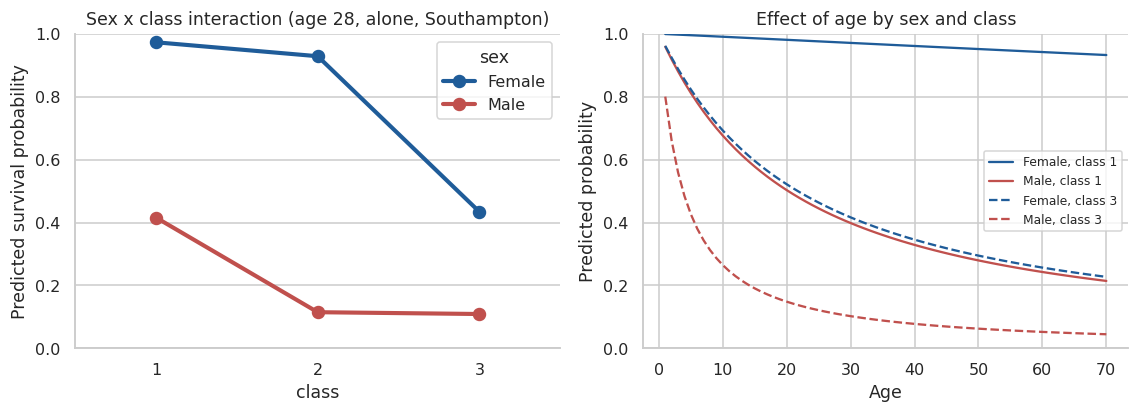

,class,sex,p
0,1,Female,0.973
1,1,Male,0.416
2,2,Female,0.929
3,2,Male,0.115
4,3,Female,0.434
5,3,Male,0.109


In [8]:
# Predicted probabilities for a reference passenger (age 28, travelling alone, Southampton)
def mk(female, cls, age=28, fam=1, port="S"):
    d = pd.DataFrame({"Female":[female], "P2":[int(cls==2)], "P3":[int(cls==3)], "LA":[np.log(age)], "Family_Size":[fam]})
    d["FS_c"] = d.Family_Size - FS_MEAN; d["FS_c2"] = d.FS_c**2; d["Emb_C"] = int(port=="C"); d["Emb_Q"] = int(port=="Q"); return d
grid = pd.DataFrame([{"class": c_, "sex": s_, "p": float(m.predict(mk(f_, c_))[0])} for c_ in (1,2,3) for s_, f_ in (("Female",1),("Male",0))])
R["pred_ref"] = grid.round(3).to_dict("records")
ages = np.arange(1, 71)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
sns.pointplot(data=grid, x="class", y="p", hue="sex", palette={"Female": BLUE, "Male": RED}, ax=ax[0]); ax[0].set_ylim(0,1); ax[0].set_ylabel("Predicted survival probability"); ax[0].set_title("Sex x class interaction (age 28, alone, Southampton)")
for cls, ls in [(1,"-"),(3,"--")]:
    for f_, col in [(1,BLUE),(0,RED)]:
        p_ = [float(m.predict(mk(f_, cls, age=a))[0]) for a in ages]; ax[1].plot(ages, p_, ls, color=col, label=f"{'Female' if f_ else 'Male'}, class {cls}")
ax[1].set_xlabel("Age"); ax[1].set_ylabel("Predicted probability"); ax[1].set_ylim(0,1); ax[1].legend(fontsize=8); ax[1].set_title("Effect of age by sex and class")
save("02_predicted_probs"); grid.round(3)

In [9]:
# Class contrasts within each sex (men: P2, P3 main effects; women: add the interaction terms)
def contrast(coefs):
    c = pd.Series(0.0, index=b.index)
    for k_, w_ in coefs.items(): c[k_] += w_
    est = float(c @ b); se = float(np.sqrt(c @ V @ c))
    return {"OR": float(np.exp(est)), "low": float(np.exp(est-1.96*se)), "high": float(np.exp(est+1.96*se)), "p": float(2*stats.norm.sf(abs(est/se)))}
cls_sex = []
for sex_, extra_ in [("Men", False), ("Women", True)]:
    cls_sex.append({"sex": sex_, "contrast": "Second vs first", **contrast({"P2": 1, **({"Female:P2": 1} if extra_ else {})})})
    cls_sex.append({"sex": sex_, "contrast": "Third vs first",  **contrast({"P3": 1, **({"Female:P3": 1} if extra_ else {})})})
    cls_sex.append({"sex": sex_, "contrast": "Third vs second",  **contrast({"P3": 1, "P2": -1, **({"Female:P3": 1, "Female:P2": -1} if extra_ else {})})})
R["class_or_by_sex"] = cls_sex
# Adjusted family-size curve: vertex of the quadratic and predicted probabilities for a mid-range reference passenger
a1, a2 = float(m.params["FS_c"]), float(m.params["FS_c2"]); R["fs_vertex"] = float(FS_MEAN - a1/(2*a2))
pred_fam = {}
for label, f_, c_ in [("Woman, third class", 1, 3), ("Man, third class", 0, 3)]:
    pred_fam[label] = {int(fs): round(float(m.predict(mk(f_, c_, fam=fs))[0]), 3) for fs in range(1, 9)}
R["pred_fam"] = pred_fam
print(pd.DataFrame(cls_sex).round(3)); print(R["fs_vertex"], pred_fam)

     sex         contrast     OR    low   high      p
0    Men  Second vs first  0.183  0.087  0.383  0.000
1    Men   Third vs first  0.172  0.100  0.298  0.000
2    Men  Third vs second  0.944  0.480  1.855  0.867
3  Women  Second vs first  0.362  0.085  1.531  0.167
4  Women   Third vs first  0.021  0.006  0.074  0.000
5  Women  Third vs second  0.059  0.023  0.152  0.000
1.7571131732303047 {'Woman, third class': {1: 0.434, 2: 0.447, 3: 0.409, 4: 0.324, 5: 0.212, 6: 0.109, 7: 0.043, 8: 0.013}, 'Man, third class': {1: 0.109, 2: 0.115, 3: 0.1, 4: 0.071, 5: 0.041, 6: 0.019, 7: 0.007, 8: 0.002}}


In [10]:
# Exploratory extension (not pre-specified): do men and women have different age slopes? (M4 = M3 + Female x log(Age))
m4 = fits["M4 + sex x age"]; b4, V4 = m4.params, m4.cov_params(); ln2 = np.log(2)
def lin4(coefs):
    c = pd.Series(0.0, index=b4.index)
    for k_, w_ in coefs.items(): c[k_] = w_
    est = float(c @ b4); se = float(np.sqrt(c @ V4 @ c)); return {"OR_doubling": float(np.exp(est*ln2)), "low": float(np.exp((est-1.96*se)*ln2)), "high": float(np.exp((est+1.96*se)*ln2)), "p": float(2*stats.norm.sf(abs(est/se)))}
c4, d4, p4, _ = hl_test(df.Survived, m4.predict(df))
R["m4"] = {"men": lin4({"LA": 1}), "women": lin4({"LA": 1, "Female:LA": 1}), "interaction_p": float(m4.pvalues["Female:LA"]), "interaction_coef": float(m4.params["Female:LA"]),
           "aic": float(m4.aic), "bic": float(m4.bic), "aic_m3": float(m.aic), "bic_m3": float(m.bic), "hl_p": p4, "mcfadden": float(m4.prsquared)}
print(R["m4"])

{'men': {'OR_doubling': 0.3905379836144638, 'low': 0.2947562099118867, 'high': 0.5174442862162085, 'p': 5.7764840934545217e-11}, 'women': {'OR_doubling': 0.7347548511282546, 'low': 0.534878684868784, 'high': 1.009321751882752, 'p': 0.0570769991663922}, 'interaction_p': 0.002020652585083396, 'interaction_coef': 0.9118001078188392, 'aic': 737.0659053360298, 'bic': 794.5740384656795, 'aic_m3': 744.0393044028332, 'bic_m3': 796.7550931050121, 'hl_p': 0.2881789595089395, 'mcfadden': 0.39909592675237493}


**Interpretation of the final model (M3)**
- **Overall fit:** likelihood-ratio chi-square = 464.6 on 10 df (p < 0.001); McFadden R-squared 0.39 and Nagelkerke R-squared 0.55. Values of 0.2 to 0.4 are considered an excellent fit for McFadden's measure.
- **H1, sex (supported in every class):** the odds of survival for women versus men of the same class, age, family size and port are about 51 in first class (95% CI 15 to 172), 100 in second class (35 to 288) and 6 in third class (3.8 to 10.3). The intervals for first and second class are wide because only 3 of 94 first-class women and 6 of 76 second-class women died, so the estimate rests on very few events.
- **H3, interaction (supported):** the female x third-class term (OR 0.12, 95% CI 0.03 to 0.46, p = 0.002) shows that the sex advantage is about eight times smaller in third class. The female x second-class term is not significant (p = 0.40), so second-class women behave like first-class women.
- **H2, class (supported, but its shape depends on sex):** among men, second and third class both have about one-sixth the odds of first class (OR 0.18 and 0.17), and second versus third class is indistinguishable (OR 0.94, p = 0.87), so first class is the outlier. Among women the pattern is reversed: second class does not differ significantly from first (OR 0.36, 95% CI 0.09 to 1.53), whereas third class has about 2% of first-class odds (OR 0.021) and 6% of second-class odds, so third class is the outlier.
- **H4, age (supported):** each doubling of age multiplies the odds of survival by 0.48 (95% CI 0.39 to 0.61), holding the other variables fixed.
- **H5, family size (supported):** the adjusted effect is an inverted U with its peak at about 1.8 people. For a third-class woman the predicted survival probability is about 43% alone, 45% with one relative, 41% with two, then 32%, 21%, 11% and 4% for family sizes 4 to 7. Very large families were at a clear disadvantage; the apparent benefit of mid-sized families in Week 2 (families of 2 to 4) is largely accounted for once sex, class and age are controlled, which suggests it reflected who those families were rather than family size itself.
- **H6, port:** after adjustment the Cherbourg (OR 1.44, 95% CI 0.89 to 2.35) and Queenstown (OR 1.51, 0.81 to 2.80) effects are not significant. The borderline Cherbourg effect seen in Week 2 disappears once the sex x class interaction is modelled, which supports the confounding explanation.
- **Reference predictions** (age 28, travelling alone, Southampton): women 97% (first), 93% (second), 43% (third); men 42%, 12% and 11%.

## 5. Model performance

In [11]:
# 5a. Hold-out evaluation: stratified 70/30 split, fit on train only
tr, te = train_test_split(df, test_size=0.30, stratify=df.Survived, random_state=42)
mt = smf.logit(F[final_name], data=tr).fit(disp=0)
p_te = mt.predict(te); y_te = te.Survived.values; pred = (p_te >= .5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
R["holdout"] = {"n_train": len(tr), "n_test": len(te), "accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
                "f1": f1_score(y_te, pred), "auc": roc_auc_score(y_te, p_te), "brier": brier_score_loss(y_te, p_te), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
                "baseline_majority": float(1 - y_te.mean()), "rule_female_survives": accuracy_score(y_te, te.Female.values)}
print({k: round(v,3) if isinstance(v,float) else v for k,v in R["holdout"].items()})

{'n_train': 623, 'n_test': 268, 'accuracy': 0.825, 'precision': 0.85, 'recall': 0.66, 'f1': 0.743, 'auc': 0.871, 'brier': 0.128, 'tn': 153, 'fp': 12, 'fn': 35, 'tp': 68, 'baseline_majority': 0.616, 'rule_female_survives': 0.776}


In [12]:
# 5b. Repeated 5-fold cross-validation (5 repeats) for nested models: does each added block improve out-of-sample skill?
def cv_model(formula, label):
    rs = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7); aucs, accs, briers = [], [], []
    for tri, tei in rs.split(df, df.Survived):
        a, b = df.iloc[tri], df.iloc[tei]; mm = smf.logit(formula, data=a).fit(disp=0); p = mm.predict(b)
        aucs.append(roc_auc_score(b.Survived, p)); accs.append(accuracy_score(b.Survived, p >= .5)); briers.append(brier_score_loss(b.Survived, p))
    return {"model": label, "AUC": np.mean(aucs), "AUC_sd": np.std(aucs), "Accuracy": np.mean(accs), "Acc_sd": np.std(accs), "Brier": np.mean(briers)}
cv = [cv_model(F[k], k) for k in ["M1 sex + class","M2 + age, family, port","M3 + sex x class","M4 + sex x age"]]
cv.insert(0, cv_model("Survived ~ Female", "Sex only"))
R["cv"] = cv; pd.DataFrame(cv).round(3)

,model,AUC,AUC_sd,Accuracy,Acc_sd,Brier
0,Sex only,0.767,0.028,0.787,0.026,0.167
1,M1 sex + class,0.833,0.031,0.787,0.026,0.149
2,"M2 + age, family, port",0.859,0.030,0.815,0.026,0.136
3,M3 + sex x class,0.865,0.033,0.817,0.028,0.130
4,M4 + sex x age,0.866,0.033,0.819,0.024,0.128


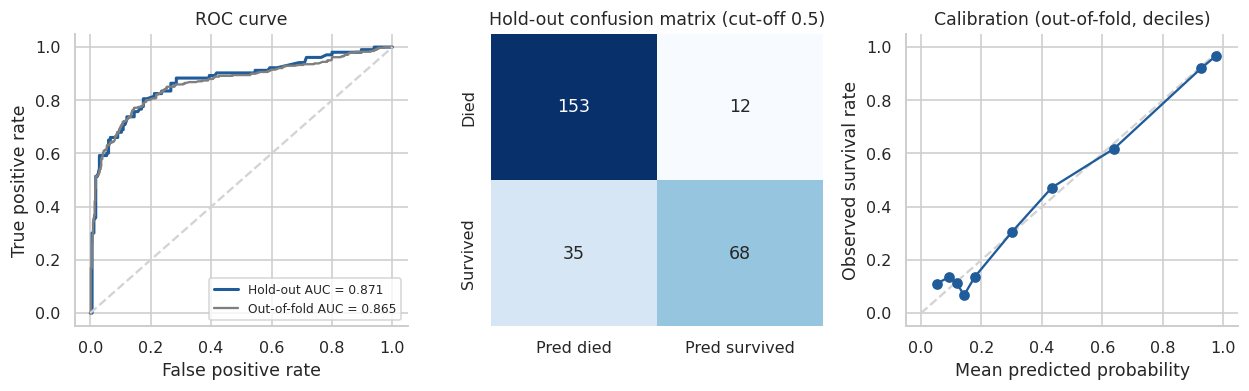

{'chi2': 8.120855659652998, 'df': 8, 'p': 0.4217545755335044} 0.8646395892585137


In [13]:
# 5c. ROC curve, confusion matrix, out-of-fold calibration and Hosmer-Lemeshow test
rs = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=11); oof = np.zeros(len(df))
for tri, tei in rs.split(df, df.Survived):
    oof[tei] = smf.logit(F[final_name], data=df.iloc[tri]).fit(disp=0).predict(df.iloc[tei])
chi2, dof, p_hl, hl_tab = hl_test(df.Survived.values, m.predict(df).values)
R["hl"] = {"chi2": chi2, "df": dof, "p": p_hl}
R["oof_auc"] = float(roc_auc_score(df.Survived, oof))
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.7))
fpr, tpr, _ = roc_curve(y_te, p_te); ax[0].plot(fpr, tpr, color=BLUE, lw=2, label=f"Hold-out AUC = {R['holdout']['auc']:.3f}")
fpr2, tpr2, _ = roc_curve(df.Survived, oof); ax[0].plot(fpr2, tpr2, color="#7F7F7F", lw=1.5, label=f"Out-of-fold AUC = {R['oof_auc']:.3f}")
ax[0].plot([0,1],[0,1],"--",c="lightgrey"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(fontsize=8, loc="lower right"); ax[0].set_title("ROC curve")
sns.heatmap([[tn, fp],[fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["Pred died","Pred survived"], yticklabels=["Died","Survived"], ax=ax[1]); ax[1].set_title("Hold-out confusion matrix (cut-off 0.5)")
cal = pd.DataFrame({"y": df.Survived, "p": oof}); cal["b"] = pd.qcut(cal.p.rank(method="first"), 10, labels=False); cg = cal.groupby("b").mean()
ax[2].plot([0,1],[0,1],"--",c="lightgrey"); ax[2].plot(cg.p, cg.y, "o-", color=BLUE); ax[2].set_xlabel("Mean predicted probability"); ax[2].set_ylabel("Observed survival rate"); ax[2].set_title("Calibration (out-of-fold, deciles)")
save("03_performance"); print(R["hl"], R["oof_auc"])

**Performance**
- **Hold-out test (268 passengers, model fitted on the other 623):** accuracy 82.5%, AUC 0.871, precision 0.85, recall 0.66, F1 0.74, Brier score 0.128. The majority-class baseline is 61.6% and the simple rule "women survive, men die" gives 77.6%, so the model beats both.
- **Repeated 5-fold cross-validation (5 repeats), mean AUC:** sex only 0.767, + class 0.833, + age, family, port 0.859, + sex x class **0.865**, + sex x age 0.866. Every block of predictors adds discrimination, and the gains from the last two steps are small. Accuracy rises from 78.7% (sex only) to 81.8%, a smaller improvement that is about one standard deviation across folds (2.8 points), so AUC and Brier score (0.167 down to 0.130) are the more reliable evidence of improvement.
- **Calibration:** the Hosmer-Lemeshow test does not detect a lack of fit (chi-square = 8.1 on 8 df, p = 0.42) and the out-of-fold calibration curve follows the diagonal closely.
- **Limitation of the cut-off:** at a threshold of 0.5 the model misses about one third of survivors (35 of 103 in the test set) while rarely mislabelling those who died (12 of 165). A lower threshold would trade precision for recall if finding survivors mattered more.

## 6. Residual analysis and influence diagnostics (logistic model)

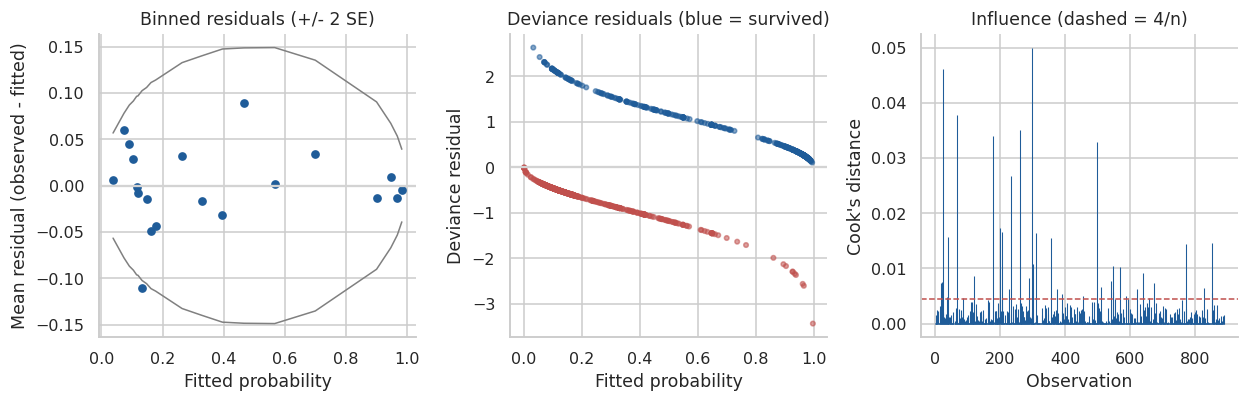

{'n_cooks_gt_4n': 38, 'max_cooks': 0.050002269342672344, 'n_lev_gt_2kn': 49, 'n_abs_dev_gt_2': 40, 'n_abs_pearson_gt_3': 23, 'dev_mean': -0.07035213263476485, 'residual_deviance': 722.0393044028331, 'null_deviance': 1186.6551368246955, 'pearson_chi2': 1214.3420783932156, 'df_resid': 880}


,PassengerId,Sex,Pclass,Age,Family_Size,Survived,cooks
297,298,Female,1,2.0,4,0,0.050
25,26,Female,3,38.0,7,1,0.046
68,69,Female,3,17.0,7,1,0.038
261,262,Male,3,3.0,7,1,0.035
177,178,Female,1,50.0,1,0,0.034


In [14]:
g = smf.glm(F[final_name], data=df, family=sm.families.Binomial()).fit()
infl = g.get_influence(); cooks = np.asarray(infl.cooks_distance[0]); lev = np.asarray(infl.hat_matrix_diag)
dev = np.asarray(g.resid_deviance); prs = np.asarray(g.resid_pearson); fitted = np.asarray(g.fittedvalues)
thr = 4/len(df)
R["resid"] = {"n_cooks_gt_4n": int((cooks > thr).sum()), "max_cooks": float(cooks.max()), "n_lev_gt_2kn": int((lev > 2*len(g.params)/len(df)).sum()),
              "n_abs_dev_gt_2": int((np.abs(dev) > 2).sum()), "n_abs_pearson_gt_3": int((np.abs(prs) > 3).sum()),
              "dev_mean": float(dev.mean()), "residual_deviance": float(g.deviance), "null_deviance": float(g.null_deviance), "pearson_chi2": float(g.pearson_chi2), "df_resid": int(g.df_resid)}
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.8))
b = pd.DataFrame({"p": fitted, "r": df.Survived.values - fitted}); b["bin"] = pd.qcut(b.p.rank(method="first"), 20, labels=False); bb = b.groupby("bin").agg(p=("p","mean"), r=("r","mean"), n=("r","size"), v=("p", lambda s: (s*(1-s)).mean()))
se = np.sqrt(bb.v/bb.n); ax[0].scatter(bb.p, bb.r, color=BLUE, s=22); ax[0].plot(bb.p, 2*se, c="grey", lw=1); ax[0].plot(bb.p, -2*se, c="grey", lw=1); ax[0].axhline(0, c="lightgrey")
ax[0].set_xlabel("Fitted probability"); ax[0].set_ylabel("Mean residual (observed - fitted)"); ax[0].set_title("Binned residuals (+/- 2 SE)")
ax[1].scatter(fitted, dev, c=np.where(df.Survived==1, BLUE, RED), s=9, alpha=.55); ax[1].axhline(0, c="lightgrey"); ax[1].set_xlabel("Fitted probability"); ax[1].set_ylabel("Deviance residual"); ax[1].set_title("Deviance residuals (blue = survived)")
ax[2].vlines(range(len(cooks)), 0, cooks, color=BLUE, lw=.7); ax[2].axhline(thr, ls="--", c=RED, lw=1); ax[2].set_xlabel("Observation"); ax[2].set_ylabel("Cook's distance"); ax[2].set_title(f"Influence (dashed = 4/n)")
save("04_logit_residuals")
inf_idx = np.where(cooks > thr)[0]; print(R["resid"]); df.iloc[np.argsort(-cooks)[:5]][["PassengerId","Sex","Pclass","Age","Family_Size","Survived"]].assign(cooks=np.sort(cooks)[::-1][:5].round(3))

**Residual and influence diagnostics**
- **Binned residuals** all lie within the plus-or-minus 2 standard-error band, i.e. no systematic over- or under-prediction at any probability level, consistent with the Hosmer-Lemeshow result.
- **Deviance residuals** form the two curved bands expected for binary outcomes; the largest are survivors with a very low predicted probability and deaths with a very high one (for example first-class women who died). 40 observations have |deviance residual| above 2 and 23 have |Pearson residual| above 3. These are surprising outcomes (for example first-class women who died) rather than evidence of misspecification: the binned residuals and the calibration test show no systematic misfit.
- **Influence:** the largest Cook's distance is 0.050, far below the level (about 1) at which a single case would matter. The 4/n rule of thumb flags 38 cases, but that rule is conservative and designed for linear models. Refitting without those cases is not informative here (see Section 7).
- **Dispersion:** residual deviance is 722 on 880 degrees of freedom. The Pearson chi-square divided by degrees of freedom is 1.38, but this statistic is unreliable for ungrouped binary data, so heteroscedasticity-robust standard errors are used as a cross-check instead.

## 7. Sensitivity analysis

In [15]:
def key_est(model_df, label, cov=None, drop_embarked=False):
    f = F[final_name]
    if drop_embarked: f = f.replace(" + Emb_C + Emb_Q", "")
    mm = smf.logit(f, data=model_df).fit(disp=0, cov_type=cov) if cov else smf.logit(f, data=model_df).fit(disp=0)
    pr = mm.params; se_ = mm.bse
    sep = bool(abs(pr["Female"]) > 12 or se_["Female"] > 50)           # quasi-complete separation in the first-class female cell
    return {"variant": label, "n": int(mm.nobs), "separation": sep,
            "OR_female_c1": None if sep else float(np.exp(pr["Female"])), "OR_class3_men": float(np.exp(pr["P3"])),
            "OR_age_doubling": float(np.exp(pr["LA"]*np.log(2))), "p_age": float(mm.pvalues["LA"]),
            "OR_female_c3": float(np.exp(pr["Female"] + pr["Female:P3"])) if not sep else None, "p_interaction_c3": None if sep else float(mm.pvalues["Female:P3"])}
sens = [key_est(df, "Final model (all 891)"),
        key_est(df, "Robust (HC0) standard errors", cov="HC0"),
        key_est(df[df.Age_Imputed == 0], "Real ages only (no imputation, n = 714)"),
        key_est(df, "Without port of embarkation", drop_embarked=True),
        key_est(df.drop(index=inf_idx), "Excluding Cook's D > 4/n cases")]
dropped = df.iloc[inf_idx]; R["sep_check"] = {"n_flagged": int(len(inf_idx)), "first_class_women_died_flagged": int(((dropped.Female==1)&(dropped.Pclass==1)&(dropped.Survived==0)).sum()), "first_class_women_died_total": int(((df.Female==1)&(df.Pclass==1)&(df.Survived==0)).sum()), "first_class_women_total": int(((df.Female==1)&(df.Pclass==1)).sum())}
R["sens"] = sens; print(R["sep_check"]); pd.DataFrame(sens).round(3)

{'n_flagged': 38, 'first_class_women_died_flagged': 3, 'first_class_women_died_total': 3, 'first_class_women_total': 94}


,variant,n,separation,OR_female_c1,OR_class3_men,OR_age_doubling,p_age,OR_female_c3,p_interaction_c3
0,Final model (all 891),891,False,50.594,0.172,0.484,0.0,6.255,0.002
1,Robust (HC0) standard errors,891,False,50.594,0.172,0.484,0.0,6.255,0.002
2,"Real ages only (no imputation, n = 714)",714,False,40.694,0.188,0.502,0.0,4.779,0.002
3,Without port of embarkation,891,False,51.850,0.165,0.477,0.0,6.663,0.002
4,Excluding Cook's D > 4/n cases,853,True,NaN,0.097,0.245,0.0,NaN,NaN


**Sensitivity analysis**
- **Robust standard errors (HC0)** leave every conclusion unchanged (interaction p = 0.002).
- **Real ages only (n = 714):** estimates move only slightly (age-doubling OR 0.50 vs 0.48; third-class men 0.19 vs 0.17; first-class women 41 vs 51; interaction p = 0.002), so the imputed ages do not drive the results.
- **Dropping port of embarkation** barely changes anything, consistent with H6.
- **Excluding cases flagged by Cook's distance (4/n):** this refit fails in an instructive way. The 38 flagged cases include **all 3** of the first-class women who died, so the remaining 91 first-class women all survived; the first-class sex effect then becomes unbounded (complete separation) and the interaction cannot be estimated. This shows that the first-class female estimate (OR 51, CI 15 to 172) rests on just three deaths and is imprecise. The other estimates remain in the same direction, so the observations were kept in the model and the wide confidence interval is reported honestly.

## 8. Supplementary linear regression: what explains the price paid per person?

Week 2 suggested that Fare is mostly a proxy for passenger class. This section tests that claim with a linear model of the log price paid per person, `log(1 + Fare_Per_Person)`, using the standard OLS diagnostics (R-squared, residual analysis, heteroscedasticity, normality, multicollinearity, influence). The model is fitted first on all passengers, the diagnostics are examined, and the remedy suggested by them is then applied.

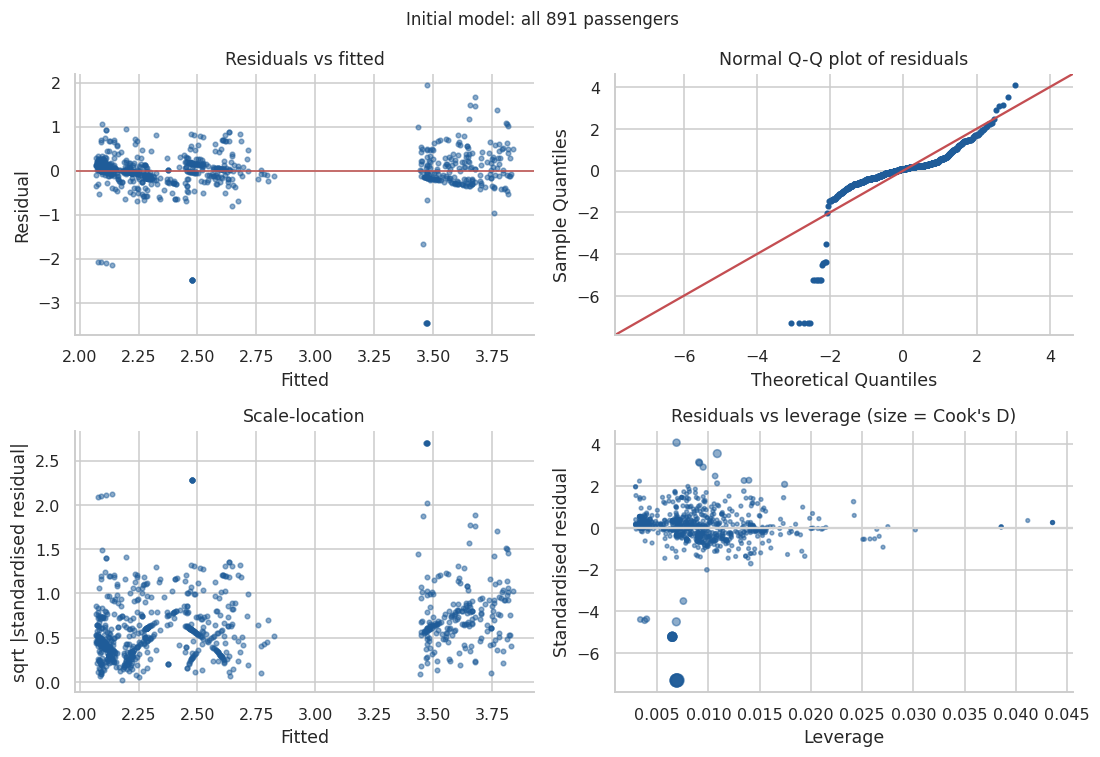

{'label': 'All passengers', 'n': 891, 'r2': 0.6131, 'adj_r2': 0.6101, 'F': 199.9287, 'F_p': 0.0, 'rmse': 0.4772, 'bp_lm': 30.4995, 'bp_p': 0.0001, 'shapiro_p': 0.0, 'jb_p': 0.0, 'resid_skew': -3.1547, 'resid_kurt': 21.3018, 'vif_max': 2.0328, 'n_cook_gt_4n': 32, 'max_cook': 0.0468}


In [16]:
df["y_fare"] = np.log1p(df.Fare_Per_Person)
OLS_TERMS = ["P2","P3","Emb_C","Emb_Q","Age","Female","Family_Size"]
FORM = lambda terms: "y_fare ~ " + " + ".join(terms)
def ols_block(data, label):
    mod = smf.ols(FORM(OLS_TERMS), data=data).fit(); hc3 = smf.ols(FORM(OLS_TERMS), data=data).fit(cov_type="HC3")
    bp = het_breuschpagan(mod.resid, mod.model.exog); infl = mod.get_influence(); ck = infl.cooks_distance[0]
    sw = stats.shapiro(mod.resid.sample(min(500, len(data)), random_state=1)); jb = stats.jarque_bera(mod.resid)
    Xo = sm.add_constant(data[OLS_TERMS]); vif_o = {c_: float(variance_inflation_factor(Xo.values, i)) for i, c_ in enumerate(Xo.columns) if c_ != "const"}
    blocks = {}
    for name, drop in {"class": ["P2","P3"], "port": ["Emb_C","Emb_Q"], "age": ["Age"], "sex": ["Female"], "family": ["Family_Size"]}.items():
        m0 = smf.ols(FORM([t for t in OLS_TERMS if t not in drop]), data=data).fit(); F_, p_, d_ = mod.compare_f_test(m0)
        blocks[name] = {"F": float(F_), "p": float(p_), "df": int(d_), "partial_R2": float((m0.ssr - mod.ssr)/m0.ssr)}
    summ = {"label": label, "n": int(mod.nobs), "r2": float(mod.rsquared), "adj_r2": float(mod.rsquared_adj), "F": float(mod.fvalue), "F_p": float(mod.f_pvalue), "rmse": float(np.sqrt(mod.mse_resid)),
            "bp_lm": float(bp[0]), "bp_p": float(bp[1]), "shapiro_p": float(sw[1]), "jb_p": float(jb[1]), "resid_skew": float(stats.skew(mod.resid)), "resid_kurt": float(stats.kurtosis(mod.resid)),
            "vif_max": max(vif_o.values()), "n_cook_gt_4n": int((ck > 4/len(data)).sum()), "max_cook": float(ck.max()), "blocks": blocks}
    return mod, hc3, infl, summ
def ols_plot(mod, infl, title, name):
    ck = infl.cooks_distance[0]; fig, ax = plt.subplots(2, 2, figsize=(10, 7)); fig.suptitle(title, fontsize=11)
    ax[0,0].scatter(mod.fittedvalues, mod.resid, s=9, alpha=.5, color=BLUE); ax[0,0].axhline(0, c=RED, lw=1); ax[0,0].set_xlabel("Fitted"); ax[0,0].set_ylabel("Residual"); ax[0,0].set_title("Residuals vs fitted")
    sm.qqplot(mod.resid, line="45", fit=True, ax=ax[0,1], markersize=3, markerfacecolor=BLUE, markeredgecolor=BLUE); ax[0,1].set_title("Normal Q-Q plot of residuals")
    ax[1,0].scatter(mod.fittedvalues, np.sqrt(np.abs(infl.resid_studentized_internal)), s=9, alpha=.5, color=BLUE); ax[1,0].set_xlabel("Fitted"); ax[1,0].set_ylabel("sqrt |standardised residual|"); ax[1,0].set_title("Scale-location")
    ax[1,1].scatter(infl.hat_matrix_diag, infl.resid_studentized_internal, s=np.clip(ck*1500, 6, 120), alpha=.5, color=BLUE); ax[1,1].axhline(0, c="lightgrey"); ax[1,1].set_xlabel("Leverage"); ax[1,1].set_ylabel("Standardised residual"); ax[1,1].set_title("Residuals vs leverage (size = Cook's D)")
    save(name)
ols_f, hc3_f, infl_f, S_full = ols_block(df, "All passengers")
ols_plot(ols_f, infl_f, "Initial model: all 891 passengers", "05a_ols_diag_full")
R["ols_full"] = S_full; print({k: (round(v,4) if isinstance(v,float) else v) for k, v in S_full.items() if k != "blocks"})

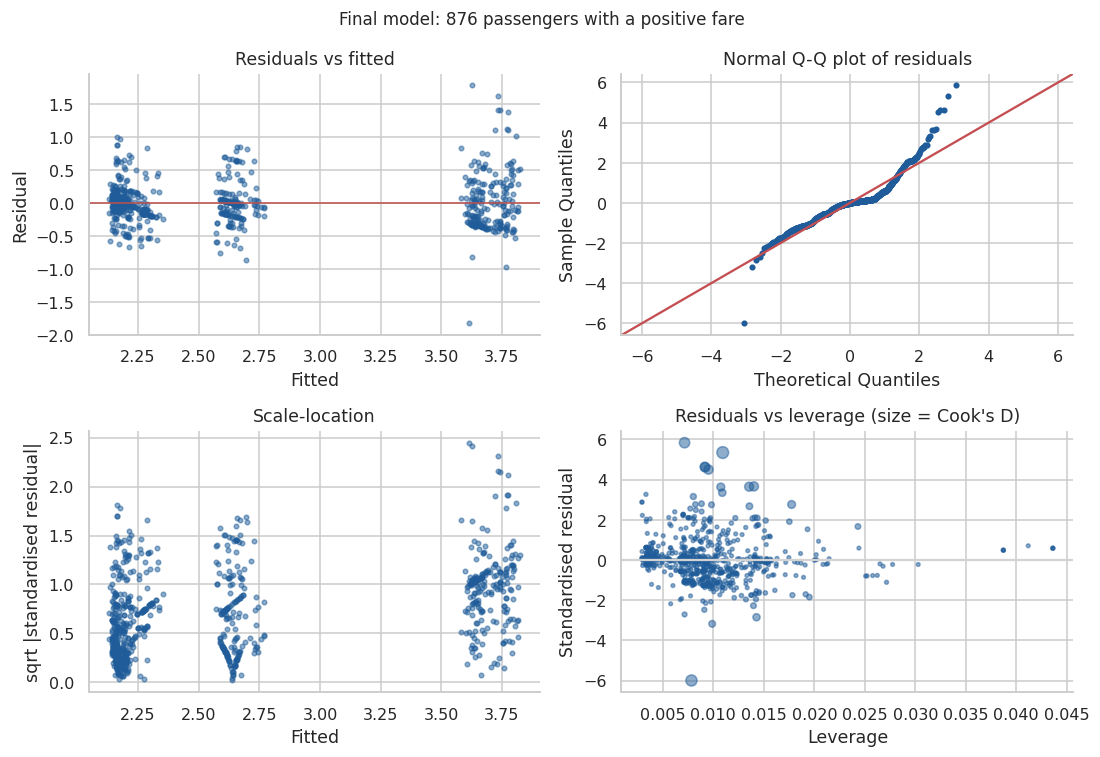

{'label': 'Excluding 15 zero-fare passengers', 'n': 876, 'r2': 0.8054, 'adj_r2': 0.8039, 'F': 513.2785, 'F_p': 0.0, 'rmse': 0.3056, 'bp_lm': 70.6114, 'bp_p': 0.0, 'shapiro_p': 0.0, 'jb_p': 0.0, 'resid_skew': 0.9857, 'resid_kurt': 5.6698, 'vif_max': 2.0408, 'n_cook_gt_4n': 59, 'max_cook': 0.0395}
{'class': {'F': 1187.0678098542862, 'p': 4.1383732040345507e-249, 'df': 2, 'partial_R2': 0.7322752340390923}, 'port': {'F': 8.614466235724247, 'p': 0.00019743785094310606, 'df': 2, 'partial_R2': 0.0194626856844223}, 'age': {'F': 3.5702557701315407, 'p': 0.05915629248489065, 'df': 1, 'partial_R2': 0.004096348798613846}, 'sex': {'F': 3.4530822183645027, 'p': 0.0634723027592916, 'df': 1, 'partial_R2': 0.00396244191319441}, 'family': {'F': 0.7373170908634941, 'p': 0.3907587220640526, 'df': 1, 'partial_R2': 0.0008487227109485111}}


,coef,se,t,p,se_HC3,p_HC3,ci_low,ci_high,ratio
Intercept,3.5551,0.0478,74.3486,0.0000,0.0574,0.0000,3.4612,3.6489,34.9902
Second class (vs first),-1.0020,0.0333,-30.0898,0.0000,0.0400,0.0000,-1.0674,-0.9367,0.3671
Third class (vs first),-1.4466,0.0297,-48.7237,0.0000,0.0375,0.0000,-1.5049,-1.3883,0.2354
Cherbourg (vs Southampton),0.1153,0.0280,4.1232,0.0000,0.0332,0.0005,0.0604,0.1702,1.1222
Queenstown (vs Southampton),0.0034,0.0384,0.0888,0.9293,0.0215,0.8740,-0.0719,0.0787,1.0034
Age (per year),0.0017,0.0009,1.8895,0.0592,0.0009,0.0774,-0.0001,0.0034,1.0017
Female (vs male),0.0421,0.0227,1.8582,0.0635,0.0244,0.0841,-0.0024,0.0866,1.0430
Family size (per person),0.0058,0.0068,0.8587,0.3908,0.0067,0.3810,-0.0075,0.0192,1.0059


In [17]:
# Diagnostics point to the 15 zero-fare passengers (log(1+0) = 0 is far below every fitted value). They were flagged in Week 1
# (crew / complimentary tickets) and follow a different process from a purchased fare, so the model is refitted without them.
nz = df[df.Fare_Zero == 0].copy()
ols_m, ols_hc3, infl_m, S_fin = ols_block(nz, "Excluding 15 zero-fare passengers")
ols_plot(ols_m, infl_m, "Final model: 876 passengers with a positive fare", "05b_ols_diag_final")
R["ols_final"] = S_fin; R["ols_class_only_r2"] = float(smf.ols("y_fare ~ P2 + P3", data=nz).fit().rsquared); R["ols_nonclass_r2"] = float(smf.ols("y_fare ~ Emb_C + Emb_Q + Age + Female + Family_Size", data=nz).fit().rsquared)
olab = {"Intercept":"Intercept","P2":"Second class (vs first)","P3":"Third class (vs first)","Emb_C":"Cherbourg (vs Southampton)","Emb_Q":"Queenstown (vs Southampton)","Age":"Age (per year)","Female":"Female (vs male)","Family_Size":"Family size (per person)"}
ot = pd.DataFrame({"coef": ols_m.params, "se": ols_m.bse, "t": ols_m.tvalues, "p": ols_m.pvalues, "se_HC3": ols_hc3.bse, "p_HC3": ols_hc3.pvalues, "ci_low": ols_m.conf_int()[0], "ci_high": ols_m.conf_int()[1], "ratio": np.exp(ols_m.params)})
ot.index = [olab[i] for i in ot.index]
R["ols_coef"] = [{"term": i, **{k: float(v) for k, v in r.items()}} for i, r in ot.iterrows()]
print({k: (round(v,4) if isinstance(v,float) else v) for k, v in S_fin.items() if k != "blocks"}); print(S_fin["blocks"]); ot.round(4)

**Linear regression: results and diagnostics**

*Initial model (all 891 passengers).* R-squared = 0.61, but the diagnostics are poor: residual skewness is -3.2 and kurtosis 21.3, the Q-Q plot shows a handful of points far below the line, and the Breusch-Pagan test rejects constant variance (p < 0.001). The extreme residuals are the **15 zero-fare passengers**: log(1 + 0) = 0 lies far below the fitted price of every class. These were flagged in Week 1 as crew or complimentary tickets, i.e. they did not buy a ticket at a market price and follow a different process, so they are excluded from the price model (the 15 records remain in the survival model).

*Final model (876 passengers with a positive fare).* R-squared = 0.805 (adjusted 0.804), residual standard error 0.31 on the log scale, F = 513 (p < 0.001), largest VIF 2.0.
- **S1 (class, supported):** class dominates. Second class pays 63% less per person than first class (ratio 0.37, 95% CI 0.34 to 0.39), and third class 76% less (ratio 0.24, CI 0.22 to 0.25). Class alone gives R-squared = 0.800, against 0.805 for the full model, while all the other predictors without class give only 0.27, so essentially all the explainable variation in price is class. This confirms quantitatively the Week 2 observation that Fare is a proxy for class.
- **S2 (port, supported but small):** Cherbourg passengers paid about 12% more per person than Southampton passengers in the same class (95% CI +6% to +19%, p < 0.001, partial R-squared 0.02); Queenstown does not differ. Age (p = 0.059), sex (p = 0.063) and family size (p = 0.39) are not significant.
- **Residuals:** the final residuals are much better behaved (skewness 1.0, kurtosis 5.7, down from -3.2 and 21.3) but still show mild right-skewness and unequal variance (Breusch-Pagan p < 0.001): first-class prices are more spread out than third-class prices, visible in the scale-location plot. Normality of residuals is rejected formally (Shapiro-Wilk p < 0.001), which with 876 observations matters little for the coefficients, and **heteroscedasticity-robust (HC3) standard errors** give the same conclusions (Cherbourg p = 0.0005, age p = 0.077, sex p = 0.084). No observation is influential (largest Cook's distance 0.04).

In [18]:
json.dump(R, open("w3_results.json", "w"), indent=1, default=str); print("saved", list(R))

saved ['assump', 'age_forms', 'age_resid_curv_p', 'compare', 'lrt', 'blocks', 'or_age_doubling', 'or_age_doubling_ci', 'coef', 'final_fit', 'sex_or_by_class', 'pred_ref', 'class_or_by_sex', 'fs_vertex', 'pred_fam', 'm4', 'holdout', 'cv', 'hl', 'oof_auc', 'resid', 'sep_check', 'sens', 'ols_full', 'ols_final', 'ols_class_only_r2', 'ols_nonclass_r2', 'ols_coef']


## 9. Conclusions, limitations and future improvements

| Hypothesis | Result |
|---|---|
| H1 Sex | **Supported** in every class (OR 51, 100 and 6 for first, second, third class) |
| H2 Class | **Supported**, with a sex-dependent shape: first class stands out among men, third class among women |
| H3 Sex x class | **Supported** (LR chi-square = 33.6, p < 0.001): the female advantage is far smaller in third class |
| H4 Age | **Supported**: doubling age multiplies the odds by 0.48; the effect is non-linear (log form) and stronger for men (exploratory) |
| H5 Family size | **Supported**: inverted U, peak at about 2 people, sharp decline beyond 3 |
| H6 Port | **Not rejected**: no independent effect (p = 0.19) |
| S1 Class explains price | **Supported**: R-squared 0.80 from class alone |
| S2 Port affects price | **Supported**, small: Cherbourg about 12% higher per person |

**Exploratory extension (M4).** Age slopes differ by sex (interaction p = 0.002): each doubling of age multiplies men's odds by 0.39 (95% CI 0.29 to 0.52) but women's by 0.73 (0.53 to 1.01). M4 has lower AIC and BIC but the same predictive skill (CV AUC 0.866 vs 0.865), and it was not pre-specified, so M3 remains the primary model.

**Limitations**
- Passengers are not independent (families and groups), so standard errors are probably too small.
- 177 ages were imputed in Week 1; the sensitivity analysis suggests this does not change the conclusions.
- The first-class female effect rests on three deaths and has a very wide interval.
- Observational historical data: the results are associations, not causal effects; unrecorded factors such as cabin location and lifeboat access are missing.
- `Fare_Per_Person` assumes the Fare column holds the total ticket price shared by everyone on the ticket.
- Hosmer-Lemeshow, Cook's distance rules and residual tests are rules of thumb, not proofs.

**Future improvements:** a mixed-effects logistic model with a random effect for ticket or family group; Firth penalised regression for the sparse first-class cell; regularised or tree-based models to compare predictive skill; a model for price with class-specific variance; and external validation on another maritime disaster dataset.

**Reproducibility:** run all cells top to bottom with `titanic_cleaned.csv` in the same folder. Random seeds are fixed for the train/test split and cross-validation folds.